# CSC2042S: Lectorial
## Backpropagation



In [1]:
# ==============================================================================
# Environment Setup & Deterministic Seeds
# ==============================================================================
# Setup reproducible seed and import foundational libraries
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
print("Environment configured successfully. Ready for modular backprop demo.")

Environment configured successfully. Ready for modular backprop demo.


<!-- ==============================================================================
CELL 2 [MARKDOWN]: SECTION 1 — Forward & Backpropagation Mechanics
============================================================================== -->
# Section 1: Backpropagation as the Gradient Engine

In this section, we implement a 2-layer Fully Connected Network ($2 \to 2 \to 1$) from scratch using NumPy.
Key architectural takeaways:
1. **Forward pass:** Stores intermediate affine sums ($z$) and activations ($h, \hat{y}$) for reuse in differentiation.
2. **Backward pass:** Applies the multivariate chain rule to evaluate $\frac{\partial \mathcal{L}}{\partial W}$ and $\frac{\partial \mathcal{L}}{\partial b}$.
3. **Modularity:** The network *does not alter its own weights*. It populates a dictionary of raw gradients `self.grads` and hands them over to an external optimiser.

In [2]:
# ==============================================================================
# Two-Layer Network with Clean Backpropagation
# ==============================================================================
class TwoLayerMLP:
    """
    Two-layer Perceptron (2 Inputs -> 2 Hidden Neurons -> 1 Output Neuron)
    Uses Sigmoid activations throughout and Squared Error Loss.
    """
    def __init__(self):
        # Weights matching our lecture worked example
        self.W1 = np.array([[0.4, 0.6],
                            [-0.2, 0.8]])   # Shape: (2, 2)
        self.b1 = np.array([0.1, -0.1])      # Shape: (2,)

        self.W2 = np.array([0.7, -0.5])      # Shape: (2,)
        self.b2 = 0.2                        # Scalar

        self.grads = {}

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

    @staticmethod
    def sigmoid_prime(a):
        return a * (1.0 - a)

    def forward(self, x):
        """Forward pass caching intermediate values."""
        self.x = x
        self.z1 = np.dot(self.W1, self.x) + self.b1
        self.h = self.sigmoid(self.z1)

        self.z2 = np.dot(self.W2, self.h) + self.b2
        self.y_hat = self.sigmoid(self.z2)
        return self.y_hat

    def backward(self, y_true):
        """
        Calculates exact gradients via the chain rule.
        DOES NOT perform weight updates.
        """
        # --- Output Layer Sensitivity (Layer 2) ---
        dL_dyhat = (self.y_hat - y_true)
        dyhat_dz2 = self.sigmoid_prime(self.y_hat)
        delta2 = dL_dyhat * dyhat_dz2

        self.grads['W2'] = delta2 * self.h
        self.grads['b2'] = delta2

        # --- Hidden Layer Sensitivity (Layer 1) ---
        delta1 = (delta2 * self.W2) * self.sigmoid_prime(self.h)

        self.grads['W1'] = np.outer(delta1, self.x)
        self.grads['b1'] = delta1

        return self.grads

# Numerical validation against our lecture boardwork
net = TwoLayerMLP()
x_in = np.array([0.5, 0.1])
y_target = 1.0

y_pred = net.forward(x_in)
loss = 0.5 * (y_pred - y_target)**2
computed_grads = net.backward(y_target)

print(f"Forward Prediction y_hat : {y_pred:.4f}  (Boardwork: 0.5932)")
print(f"Calculated Loss L         : {loss:.4f}    (Boardwork: 0.0827)")
print(f"Output Weight Grads dL/dW2: {computed_grads['W2']} (Boardwork: [-0.0578, -0.0462])")
print(f"Output Bias Grad dL/db2   : {computed_grads['b2']:.4f} (Boardwork: -0.0982)")

Forward Prediction y_hat : 0.5932  (Boardwork: 0.5932)
Calculated Loss L         : 0.0827    (Boardwork: 0.0827)
Output Weight Grads dL/dW2: [-0.05781948 -0.04613814] (Boardwork: [-0.0578, -0.0462])
Output Bias Grad dL/db2   : -0.0982 (Boardwork: -0.0982)


<!-- ==============================================================================
 SECTION 2 — Building Modular Optimisers
============================================================================== -->
# Section 2: Building Modular Optimisers

Here we implement four modular optimiser classes. Each exposes an identical `.update(params, grads)` method:
1. **Vanilla SGD:** Fixed step along the negative gradient: $\theta \leftarrow \theta - \eta g$.
2. **Momentum:** Accumulates velocity to damp oscillations and maintain speed along flat valleys: $v \leftarrow \beta v + \eta g, \; \theta \leftarrow \theta - v$.
Update:
$$\mathbf{v}_t = \beta \mathbf{v}_{t-1} + \eta \mathbf{g}_t, \qquad \mathbf{w}_{t+1} = \mathbf{w}_t - \mathbf{v}_t$$
3. **RMSprop:** Scales per-parameter step sizes inversely by a running root-mean-square of squared gradients: $s \leftarrow \beta s + (1-\beta)g^2$.

Update: $$\mathbf{s}_t = \beta \mathbf{s}_{t-1} + (1 - \beta) \mathbf{g}_t^2, \qquad \mathbf{w}_{t+1} = \mathbf{w}_t - \frac{\eta}{\sqrt{\mathbf{s}_t} + \epsilon} \odot \mathbf{g}_t$$
4. **Adam:** Combines momentum (running mean) and RMSprop (running variance) with finite-step bias corrections.

In [3]:
# ==============================================================================
# Optimiser Implementations
# ==============================================================================
class SGDoptimiser:
    def __init__(self, lr=0.1):
        self.lr = lr

    def update(self, params, grads):
        for key in params:
            params[key] -= self.lr * grads[key]

class Momentumoptimiser:
    def __init__(self, lr=0.1, beta=0.9):
        self.lr = lr
        self.beta = beta
        self.v = {}

    def update(self, params, grads):
        for key in params:
            if key not in self.v:
                self.v[key] = np.zeros_like(params[key])
            self.v[key] = self.beta * self.v[key] + self.lr * grads[key]
            params[key] -= self.v[key]

class RMSpropoptimiser:
    def __init__(self, lr=0.1, beta=0.99, eps=1e-8):
        self.lr = lr
        self.beta = beta
        self.eps = eps
        self.s = {}

    def update(self, params, grads):
        for key in params:
            if key not in self.s:
                self.s[key] = np.zeros_like(params[key])
            self.s[key] = self.beta * self.s[key] + (1 - self.beta) * (grads[key] ** 2)
            params[key] -= (self.lr / (np.sqrt(self.s[key]) + self.eps)) * grads[key]

class Adamoptimiser:
    def __init__(self, lr=0.1, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.m = {}
        self.v = {}
        self.t = 0

    def update(self, params, grads):
        self.t += 1
        for key in params:
            if key not in self.m:
                self.m[key] = np.zeros_like(params[key])
                self.v[key] = np.zeros_like(params[key])

            # Running first and second moments
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * (grads[key] ** 2)

            # Bias correction
            m_hat = self.m[key] / (1.0 - self.beta1 ** self.t)
            v_hat = self.v[key] / (1.0 - self.beta2 ** self.t)

            params[key] -= (self.lr / (np.sqrt(v_hat) + self.eps)) * m_hat

print("optimiser classes registered successfully.")

optimiser classes registered successfully.


<!-- ==============================================================================
SECTION 3 — Comparative Trajectory Experiment
============================================================================== -->
# Section 3: Trajectory Comparison on an Ill-Conditioned Valley

To illustrate why modern optimisers are necessary, consider this narrow quadratic surface:
$$f(w_1, w_2) = 0.1 w_1^2 + 2.0 w_2^2$$
* Along $w_1$, the curvature is gentle: $\frac{\partial f}{\partial w_1} = 0.2 w_1$.
* Along $w_2$, the canyon walls are steep: $\frac{\partial f}{\partial w_2} = 4.0 w_2$.

We feed identical analytical backpropagation gradients $\mathbf{g} = [0.2w_1, 4.0w_2]^T$ to all four optimisers and track their parameter trajectories $\mathbf{w}_t$.

In [4]:
# ==============================================================================
# Trajectory Simulation with Exact Convergence Tracking
# ==============================================================================
def loss_landscape(w1, w2):
    return 0.1 * (w1 ** 2) + 2.0 * (w2 ** 2)

def analytical_backprop(w1, w2):
    # Simulates backprop returning partial derivatives
    return {'w1': 0.2 * w1, 'w2': 4.0 * w2}

start_coords = {'w1': -8.0, 'w2': 3.5}
max_steps = 250
convergence_tolerance = 1e-2  # Distance threshold to minimum (0, 0): ||w||_2 < tol

optimisers = {
    'Vanilla SGD': SGDoptimiser(lr=0.35),
    'SGD + Momentum': Momentumoptimiser(lr=0.1, beta=0.85),
    'RMSprop': RMSpropoptimiser(lr=0.35, beta=0.9),
    'Adam': Adamoptimiser(lr=0.6, beta1=0.85, beta2=0.99)
}

trajectories = {}
convergence_stats = {}

for name, opt in optimisers.items():
    p = {'w1': float(start_coords['w1']), 'w2': float(start_coords['w2'])}
    path = [(p['w1'], p['w2'])]
    steps_to_converge = None

    for step in range(1, max_steps + 1):
        g = analytical_backprop(p['w1'], p['w2'])
        opt.update(p, g)
        path.append((p['w1'], p['w2']))

        # Check convergence distance to global minimum (0, 0)
        dist_to_min = np.sqrt(p['w1']**2 + p['w2']**2)
        if steps_to_converge is None and dist_to_min < convergence_tolerance:
            steps_to_converge = step

    trajectories[name] = np.array(path)
    final_loss = loss_landscape(p['w1'], p['w2'])
    convergence_stats[name] = {
        'steps': steps_to_converge if steps_to_converge is not None else f">{max_steps} (Did not converge)",
        'final_dist': np.sqrt(p['w1']**2 + p['w2']**2),
        'final_loss': final_loss
    }

# Display convergence summary
print(f"{'optimiser':<18} | {'Steps to Minimum':<22} | {'Final Distance':<16} | {'Final Loss':<12}")
print("-" * 75)
for name, stats in convergence_stats.items():
    steps_str = str(stats['steps'])
    print(f"{name:<18} | {steps_str:<22} | {stats['final_dist']:<16.4e} | {stats['final_loss']:<12.4e}")

optimiser          | Steps to Minimum       | Final Distance   | Final Loss  
---------------------------------------------------------------------------
Vanilla SGD        | 93                     | 1.0564e-07       | 1.1160e-15  
SGD + Momentum     | 68                     | 7.2034e-09       | 5.8597e-17  
RMSprop            | 39                     | 2.4765e-01       | 6.4318e-02  
Adam               | 68                     | 8.3224e-09       | 8.0209e-17  


<>:35: SyntaxWarning: invalid escape sequence '\e'
<>:35: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_12424/3320947142.py:35: SyntaxWarning: invalid escape sequence '\e'
  plt.suptitle(f"Convergence Rates on Ill-Conditioned Valley ($\epsilon = {convergence_tolerance}$)", fontsize=14, fontweight='bold')


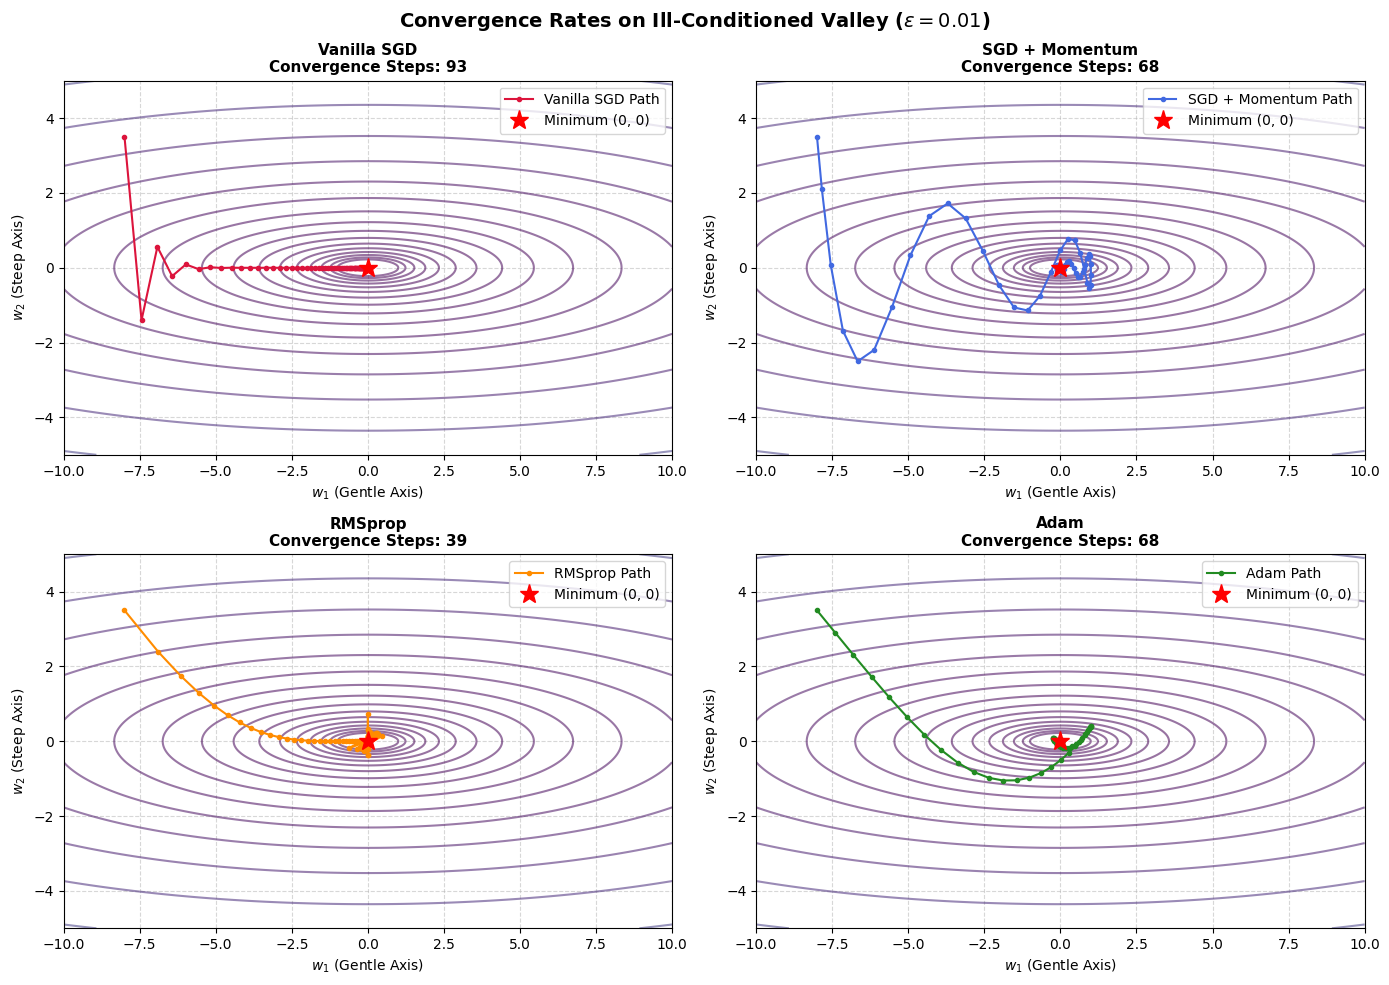

In [5]:
# ==============================================================================
# Comparative Trajectory Plots with Convergence Annotations
# ==============================================================================
w1_grid = np.linspace(-10, 10, 400)
w2_grid = np.linspace(-5, 5, 400)
W1_mesh, W2_mesh = np.meshgrid(w1_grid, w2_grid)
Z_loss = loss_landscape(W1_mesh, W2_mesh)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

palette = {
    'Vanilla SGD': 'crimson',
    'SGD + Momentum': 'royalblue',
    'RMSprop': 'darkorange',
    'Adam': 'forestgreen'
}

for i, (name, path) in enumerate(trajectories.items()):
    ax = axes[i]
    ax.contour(W1_mesh, W2_mesh, Z_loss, levels=np.logspace(-1, 2.5, 20), cmap='viridis', alpha=0.55)
    ax.plot(path[:, 0], path[:, 1], marker='o', markersize=3, color=palette[name], label=f"{name} Path", linewidth=1.5)
    ax.plot(0, 0, 'r*', markersize=14, label="Minimum (0, 0)")

    # Title annotated with convergence steps
    step_info = convergence_stats[name]['steps']
    ax.set_title(f"{name}\nConvergence Steps: {step_info}", fontsize=11, fontweight='bold')
    ax.set_xlabel("$w_1$ (Gentle Axis)", fontsize=10)
    ax.set_ylabel("$w_2$ (Steep Axis)", fontsize=10)
    ax.set_xlim([-10, 10])
    ax.set_ylim([-5, 5])
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right')

plt.suptitle(f"Convergence Rates on Ill-Conditioned Valley ($\epsilon = {convergence_tolerance}$)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

<!-- ==============================================================================
SECTION 4 — PyTorch Implementation
============================================================================== -->
# SECTION 4 — PyTorch Implementation


In PyTorch, backpropagation is handled automatically through its reverse-mode automatic differentiation engine (Autograd). Instead of computing and writing out multivariate chain-rule derivatives by hand, calling loss.backward() traverses the directed acyclic graph (DAG) constructed during the forward pass and accumulates the gradients directly into each parameter's .grad attribute.

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Define Model Architecture
class SimpleMLP(nn.Module):
    def __init__(self):
        super(SimpleMLP, self).__init__()
        self.fc1 = nn.Linear(in_features=2, out_features=2)
        self.act = nn.Sigmoid()
        self.fc2 = nn.Linear(in_features=2, out_features=1)
        self.out_act = nn.Sigmoid()

    def forward(self, x):
        h = self.act(self.fc1(x))
        y_hat = self.out_act(self.fc2(h))
        return y_hat

# 2. Instantiate Components
model = SimpleMLP()
criterion = nn.MSELoss()                           # Computes Mean Squared Error
optimiser = optim.SGD(model.parameters(), lr=0.5)  # Can swap with Adam, RMSprop, etc.

# Sample data
x_train = torch.tensor([[0.5, 0.1]], dtype=torch.float32)
y_train = torch.tensor([[1.0]], dtype=torch.float32)

# ==============================================================================
# THE CANONICAL PYTORCH TRAINING LOOP
# ==============================================================================
for epoch in range(100):
    # 1. Clear old gradients from previous iterations
    optimiser.zero_grad()

    # 2. Forward pass: compute predictions and error
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # 3. Backpropagation: calculates and stores dLoss/dtheta in param.grad
    loss.backward()

    # 4. Optimization step: update parameters via optimiser rule (e.g., theta - lr * grad)
    optimiser.step()